# Разведочный анализ данных (EDA)
## Датасет Default of Credit Card Clients (UCI)

Смотрю целевую переменную, ключевые распределения и связи признаков с дефолтом. Данные - очищенная версия из этапа prepare

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/processed/processed.csv")
print("Строк:", len(df))
print("Доля дефолта:", round(df["default"].mean(), 4))
df["default"].value_counts(normalize=True)

Строк: 30000
Доля дефолта: 0.2212


default
0    0.7788
1    0.2212
Name: proportion, dtype: float64

Дисбаланс классов умеренный: примерно 78% нулей и 22% дефолтов. Учитываю это в метриках - точность на дефолтном классе важнее общей accuracy

### Распределение кредитного лимита по классам

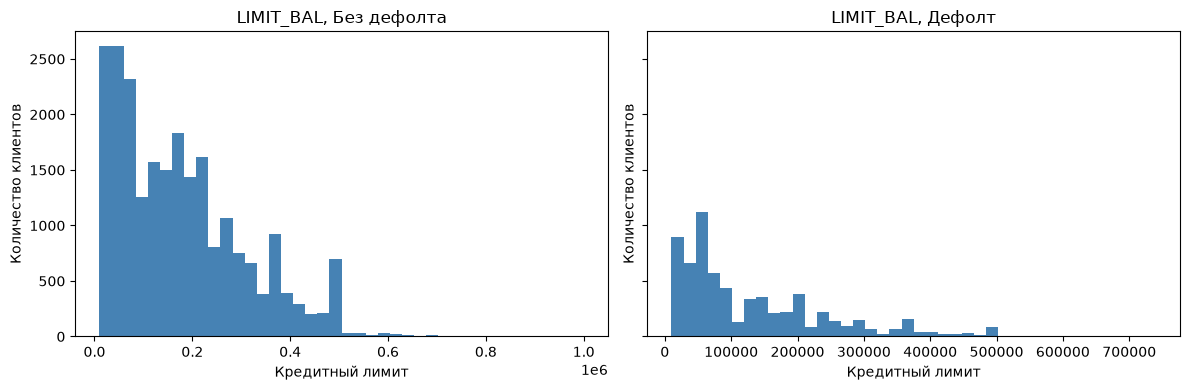

Медианный лимит, без дефолта: 150000.0
Медианный лимит, дефолт: 90000.0


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, cls, title in zip(axes, [0, 1], ["Без дефолта", "Дефолт"]):
    ax.hist(df[df["default"] == cls]["LIMIT_BAL"], bins=40, color="steelblue")
    ax.set_title(f"LIMIT_BAL, {title}")
    ax.set_xlabel("Кредитный лимит")
    ax.set_ylabel("Количество клиентов")
plt.tight_layout()
plt.show()

print("Медианный лимит, без дефолта:", df[df['default'] == 0]['LIMIT_BAL'].median())
print("Медианный лимит, дефолт:", df[df['default'] == 1]['LIMIT_BAL'].median())

У клиентов с дефолтом медианный лимит ниже - лимит уже несёт прогнозную силу

### Доля дефолтов по возрастным группам

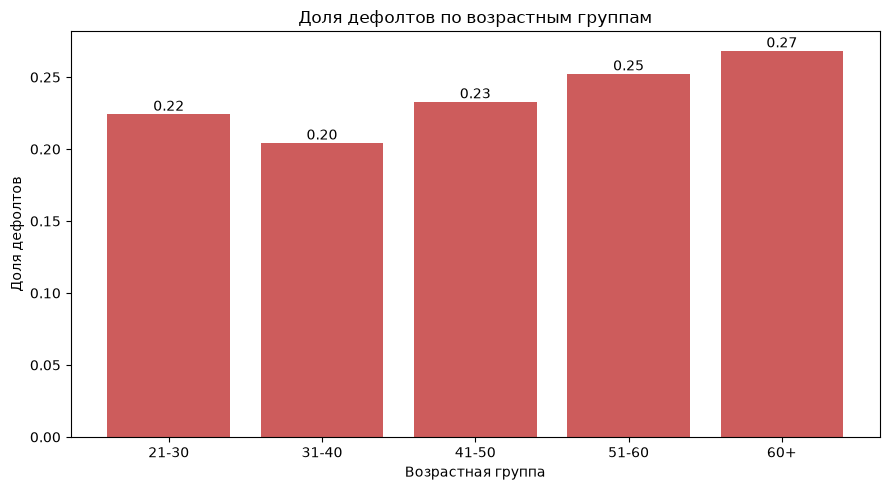

,mean,count
age_group,,
21-30,0.224371,11013
31-40,0.204331,10713
41-50,0.232973,6005
51-60,0.252379,1997
60+,0.268382,272


In [3]:
age_rate = df.groupby("age_group")["default"].agg(["mean", "count"])

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.bar(age_rate.index, age_rate["mean"], color="indianred")
ax1.set_xlabel("Возрастная группа")
ax1.set_ylabel("Доля дефолтов")
ax1.set_title("Доля дефолтов по возрастным группам")
for i, (idx, row) in enumerate(age_rate.iterrows()):
    ax1.text(i, row["mean"], f"{row['mean']:.2f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

age_rate

Молодая группа 21-30 рискует сильнее остальных, с возрастом доля дефолтов снижается. Биннинг возраста в признаках помогает модели ухватить эту нелинейность

### Связь статусов платежей с дефолтом

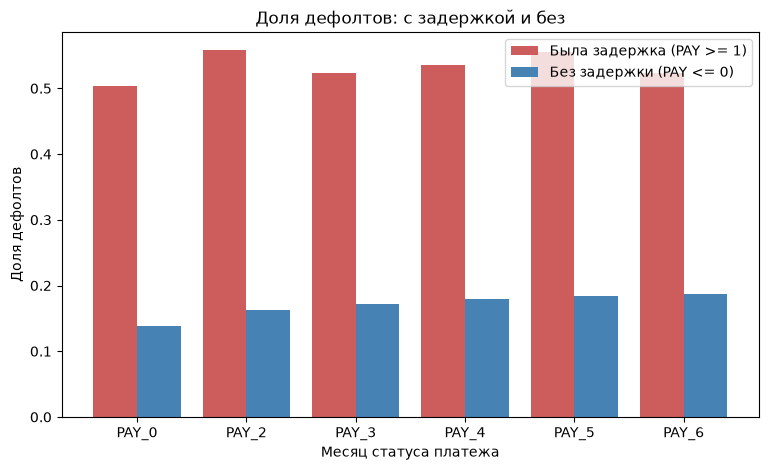

Доля дефолтов при задержке в сентябре (PAY_0 >= 1): 0.503
Доля дефолтов без задержки: 0.138


In [4]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
pay_rates = [df[df[p] >= 1]["default"].mean() for p in pay_cols]
pay_rates_ok = [df[df[p] <= 0]["default"].mean() for p in pay_cols]

plt.figure(figsize=(9, 5))
x = range(len(pay_cols))
plt.bar([i - 0.2 for i in x], pay_rates, width=0.4, label="Была задержка (PAY >= 1)", color="indianred")
plt.bar([i + 0.2 for i in x], pay_rates_ok, width=0.4, label="Без задержки (PAY <= 0)", color="steelblue")
plt.xticks(list(x), pay_cols)
plt.title("Доля дефолтов: с задержкой и без")
plt.xlabel("Месяц статуса платежа")
plt.ylabel("Доля дефолтов")
plt.legend()
plt.show()

print("Доля дефолтов при задержке в сентябре (PAY_0 >= 1):", round(df[df['PAY_0'] >= 1]['default'].mean(), 3))
print("Доля дефолтов без задержки:", round(df[df['PAY_0'] <= 0]['default'].mean(), 3))

Задержка платежа резко повышает риск дефолта: у клиентов с PAY >= 1 дефолты встречаются в разы чаще. Поэтому агрегаты из истории платежей (pay_mean_delay, pay_late_count) в признаках - самое сильное добавление

### Корреляции числовых признаков с целевой

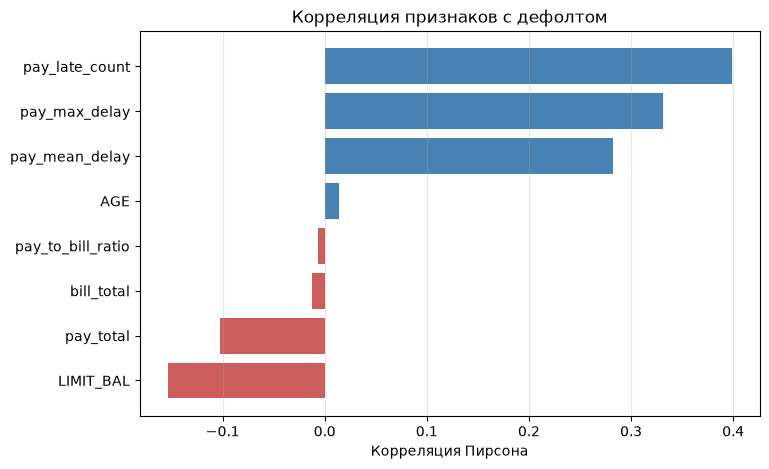

LIMIT_BAL           -0.153520
pay_total           -0.102354
bill_total          -0.012691
pay_to_bill_ratio   -0.006874
AGE                  0.013890
pay_mean_delay       0.281955
pay_max_delay        0.331036
pay_late_count       0.398394
Name: default, dtype: float64

In [5]:
num_cols = ["LIMIT_BAL", "AGE", "pay_mean_delay", "pay_max_delay", "pay_late_count",
            "bill_total", "pay_total", "pay_to_bill_ratio", "default"]
corr = df[num_cols].corr()["default"].drop("default").sort_values()

plt.figure(figsize=(8, 5))
colors = ["indianred" if v < 0 else "steelblue" for v in corr.values]
plt.barh(corr.index, corr.values, color=colors)
plt.title("Корреляция признаков с дефолтом")
plt.xlabel("Корреляция Пирсона")
plt.grid(alpha=0.3, axis="x")
plt.show()

corr

In [6]:
df.groupby("default")[["LIMIT_BAL", "AGE", "pay_mean_delay", "bill_total", "pay_total"]].median()

,LIMIT_BAL,AGE,pay_mean_delay,bill_total,pay_total
default,,,,,
0,150000.0,34.0,0.000000,128660.5,16524.0
1,90000.0,34.0,0.333333,118688.0,9674.5


Итог EDA: смещение классов (22% дефолтов), лимит и история задержек связаны с дефолтом, молодые клиенты рискованнее. Эти наблюдения легли в основу признаков и выбора метрик (ROC-AUC и F1 вместо accuracy)